<a href="https://colab.research.google.com/github/SarthC/AIML-LAB-/blob/main/Assignment6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd
import numpy as np
from scipy import stats

# Load dataset
df = pd.read_csv("/content/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv")
df.columns = df.columns.str.strip()

# Select numerical data and clean it
data = df.select_dtypes(include=np.number)
data = data.replace([np.inf, -np.inf], np.nan).dropna()


print("Mean:\n", data.mean())
print("\nMedian:\n", data.median())
print("\nStandard Deviation:\n", data.std())


Q1, Q3 = data.quantile(0.25), data.quantile(0.75)
IQR = Q3 - Q1
print("\nOutliers:\n", ((data < Q1 - 1.5*IQR) |
                       (data > Q3 + 1.5*IQR)).sum())

print("\nCorrelation:\n", data.corr())


df["Label"] = df["Label"].astype(str).str.strip().str.upper()
feature = "Flow Duration"

if feature in df.columns:
    benign = pd.to_numeric(
        df.loc[df["Label"] == "BENIGN", feature],
        errors="coerce"
    ).dropna()

    attack = pd.to_numeric(
        df.loc[df["Label"] != "BENIGN", feature],
        errors="coerce"
    ).dropna()

    t, p = stats.ttest_ind(benign, attack, equal_var=False)
    print("\nT-test p-value:", p)
    print("Significant difference" if p < 0.05
          else "No significant difference")


Mean:
 Destination Port               8.015815e+03
Flow Duration                  5.386306e+06
Total Fwd Packets              3.476305e+00
Total Backward Packets         3.523953e+00
Total Length of Fwd Packets    2.337033e+02
                                   ...     
Active Min                     2.174195e+04
Idle Mean                      1.605051e+06
Idle Std                       6.128327e+04
Idle Max                       1.649324e+06
Idle Min                       1.538278e+06
Length: 78, dtype: float64

Median:
 Destination Port               1108.0
Flow Duration                    65.0
Total Fwd Packets                 1.0
Total Backward Packets            1.0
Total Length of Fwd Packets       2.0
                                ...  
Active Min                        0.0
Idle Mean                         0.0
Idle Std                          0.0
Idle Max                          0.0
Idle Min                          0.0
Length: 78, dtype: float64

Standard Deviation:
 Desti

Class counts:
 Label
BENIGN      123295
PortScan     90819
Name: count, dtype: int64


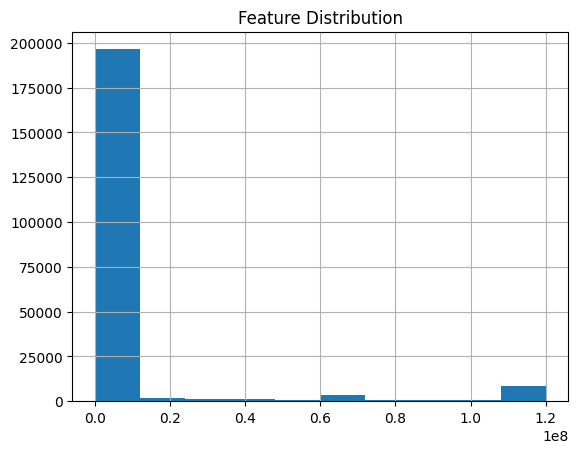

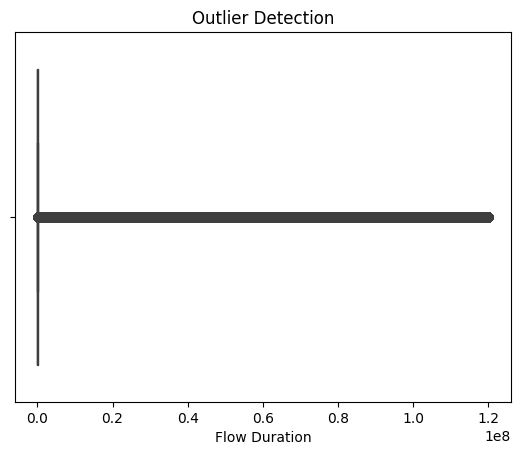

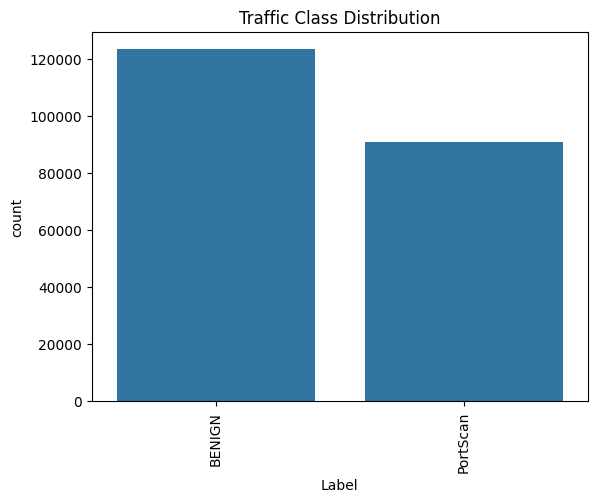

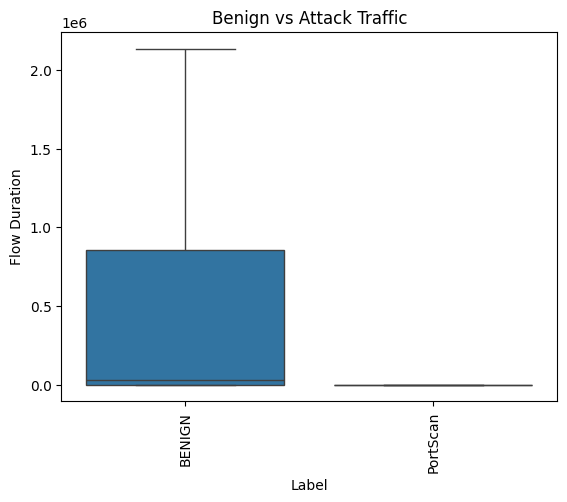

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


df = pd.read_csv("/content/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv")
df.columns = df.columns.str.strip()
df = df.replace([np.inf, -np.inf], np.nan).drop_duplicates()
df["Label"] = df["Label"].astype(str).str.strip()


for c in df.select_dtypes(include=np.number):
    df[c] = df[c].fillna(df[c].median())

print("Class counts:\n", df["Label"].value_counts())


feature = "Flow Duration"
if feature not in df.columns:
    feature = df.select_dtypes(include=np.number).columns[0]


df[feature].hist()
plt.title("Feature Distribution")
plt.show()




sns.boxplot(x=df[feature])
plt.title("Outlier Detection")
plt.show()


sns.countplot(data=df, x="Label")
plt.xticks(rotation=90)
plt.title("Traffic Class Distribution")
plt.show()


sns.boxplot(data=df, x="Label", y=feature, showfliers=False)
plt.xticks(rotation=90)
plt.title("Benign vs Attack Traffic")
plt.show()


if "Protocol" in df.columns:
    sns.countplot(data=df, x="Protocol", hue="Label")
    plt.title("Protocol-wise Traffic")
    plt.show()



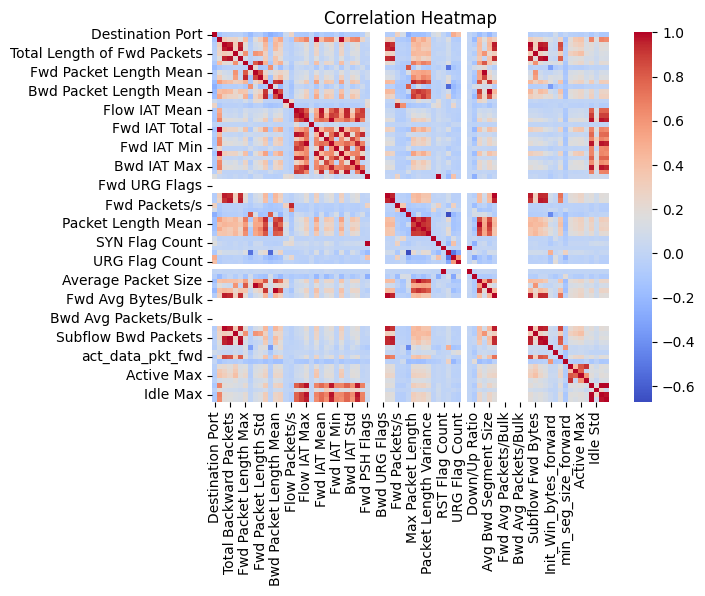

Unusual flows:
     Destination Port  Flow Duration  Total Fwd Packets  \
0                 22        1266342                 41   
1                 22        1319353                 41   
3                 22        1303488                 41   
6                 22        1307239                 41   
14                21         152547                 19   

    Total Backward Packets  Total Length of Fwd Packets  \
0                       44                         2664   
1                       44                         2664   
3                       42                         2728   
6                       40                         2728   
14                      25                          206   

    Total Length of Bwd Packets  Fwd Packet Length Max  Fwd Packet Length Min  \
0                          6954                    456                      0   
1                          6954                    456                      0   
3                          6634      

In [ ]:

data = df.select_dtypes(include=np.number)
sns.heatmap(data.corr(), cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()


q1, q3 = df[feature].quantile([0.25, 0.75])
iqr = q3 - q1
unusual = df[(df[feature] < q1 - 1.5*iqr) |
             (df[feature] > q3 + 1.5*iqr)]
print("Unusual flows:\n", unusual.head())
